# 07 – Mô hình chính, giai đoạn giữa kỳ (BRFSS 2015)

**Thực hiện**
1. Logistic Regression với `class_weight="balanced"` (kèm 2 biến thể để so sánh: không dùng đặc trưng mới, và one-hot biến thứ tự).
2. Random Forest với `class_weight="balanced_subsample"`, tuning nhẹ (vài giá trị `max_depth`).
3. Với mỗi mô hình: Macro F1, Precision/Recall/F1 theo lớp, ROC-AUC, PR-AUC, confusion matrix.
4. So sánh với baseline từ notebook 06 và viết nhận xét ban đầu.

**Cần chạy notebook 06 trước** (để có `logs/results_06_baseline.csv`). Cùng cách chia dữ liệu, pipeline và bộ CV với 06. Tập test không được dùng.



## 0. Cấu hình, nạp dữ liệu và hàm dùng chung
Phần này giống hệt giữa notebook 06 và 07, để hai notebook dùng **cùng một cách chia dữ liệu, cùng pipeline và cùng bộ CV**.

In [1]:
from pathlib import Path
import csv, os, time, warnings
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support,
                             roc_auc_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# ---------------- CẤU HÌNH (sửa ở đây) ----------------
RUNNER       = "Quang Khu"          # ghi vào Experiment Log
TARGET       = "Diabetes_binary"    # đổi thành "Diabetes_012" nếu nhóm quyết định dùng nhãn 3 lớp
RAW_FILE     = "diabetes.csv"       # file trong DATA/raw/ (nếu dùng 3 lớp, đổi tên file tương ứng)
DEDUP        = False                # False = giữ dòng trùng (giống notebook 05); True = xóa trùng trước khi chia (giống notebook 03)
RANDOM_STATE = 42                   # dùng chung cả nhóm
TEST_SIZE    = 0.20
QUICK        = False                # True = chạy thử nhanh trên mẫu nhỏ để kiểm tra code
QUICK_N      = 20000

CLASS_NAMES_BY_TARGET = {
    "Diabetes_binary": ["Không tiểu đường", "Tiểu đường/tiền TĐ"],
    "Diabetes_012":    ["Không bệnh", "Tiền tiểu đường", "Tiểu đường"],
}

In [2]:
def find_project_root():
    """Giống notebook 04/05: đi ngược lên đến thư mục có DATA/ hoặc sources/."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "DATA").is_dir() or (base / "sources").is_dir():
            return base
    raise FileNotFoundError("Không tìm thấy thư mục DATA/ hoặc sources/. Hãy mở notebook trong thư mục dự án.")

ROOT = find_project_root()
RAW_PATH = next((p for p in [ROOT / "DATA" / "raw" / RAW_FILE, ROOT / "sources" / RAW_FILE] if p.is_file()), None)
if RAW_PATH is None:
    raise FileNotFoundError(f"Không tìm thấy {RAW_FILE} trong DATA/raw/ hoặc sources/.")

FIG_DIR = ROOT / "DATA" / "figures"      # cùng chỗ với hình của notebook 02
LOG_DIR = ROOT / "logs"                  # Experiment Log dùng chung cả nhóm
FIG_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_PATH = LOG_DIR / "experiment_log.csv"
print("Project:", ROOT)
print("Dữ liệu:", RAW_PATH.relative_to(ROOT))

Project: d:\May Hoc\CK_ML\MAY_HOC_NHOM\Do_An_Cuoi_Ky
Dữ liệu: DATA\raw\diabetes.csv


In [3]:
df = pd.read_csv(RAW_PATH)
if TARGET not in df.columns:
    raise ValueError(f"Không có cột {TARGET}. Các cột hiện có: {list(df.columns)}")
n_raw = len(df)
if DEDUP:
    df = df.drop_duplicates(keep="first").reset_index(drop=True)
    print(f"Xóa trùng: {n_raw:,} -> {len(df):,} dòng")
else:
    print(f"Giữ dòng trùng: {n_raw:,} dòng (trong đó {df.duplicated().sum():,} dòng trùng)")

X = df.drop(columns=TARGET).copy()
y = df[TARGET].astype(int).copy()

# Chia y hệt notebook 05: 80/20, phân tầng, seed 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
del X_test, y_test        # KHÔNG dùng tập test ở giữa kỳ; chỉ dùng một lần ở cuối

if QUICK:
    X_train, _, y_train, _ = train_test_split(
        X_train, y_train, train_size=QUICK_N, stratify=y_train, random_state=RANDOM_STATE)

X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
yv = y_train.values

CLASSES = sorted(y_train.unique().tolist())
CLASS_NAMES = CLASS_NAMES_BY_TARGET.get(TARGET, [str(c) for c in CLASSES])
counts = y_train.value_counts().sort_index()
FOCUS_IDX = int(np.argmin(counts.values))      # lớp hiếm nhất = lớp cần chú ý
FOCUS_NAME = CLASS_NAMES[FOCUS_IDX]
DATA_TAG = f"{TARGET}|{'dedup' if DEDUP else 'giữ trùng'}|{'QUICK' if QUICK else 'đầy đủ'}"

print("X_train:", X_train.shape, "| Số lớp:", len(CLASSES), "| Lớp cần chú ý:", FOCUS_NAME)
print(pd.DataFrame({"số mẫu": counts.values, "tỷ lệ": (counts / counts.sum()).round(4).values},
                   index=CLASS_NAMES))

Giữ dòng trùng: 253,680 dòng (trong đó 24,206 dòng trùng)
X_train: (202944, 21) | Số lớp: 2 | Lớp cần chú ý: Tiểu đường/tiền TĐ
                    số mẫu   tỷ lệ
Không tiểu đường    174667  0.8607
Tiểu đường/tiền TĐ   28277  0.1393


In [4]:
# ----- Sao chép từ notebook 05 (nên chuyển vào src/ để cả nhóm import chung, tránh lệch phiên bản) -----
ORDINAL = ["Age", "Education", "Income", "GenHlth"]

class Winsorizer(BaseEstimator, TransformerMixin):
    """Cắt BMI về các phân vị lower/upper đã ước lượng trong fit."""
    def __init__(self, columns=("BMI",), lower=0.01, upper=0.99):
        self.columns = columns
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.bounds_ = {col: (X[col].quantile(self.lower), X[col].quantile(self.upper))
                        for col in self.columns}
        return self

    def transform(self, X):
        out = X.copy()
        for col, (low, high) in self.bounds_.items():
            out[col] = out[col].clip(low, high)
        return out

class HealthFeatureEngineer(BaseEstimator, TransformerMixin):
    """Tạo các đặc trưng bổ sung, giữ các cột gốc."""
    def __init__(self, interaction=True):
        self.interaction = interaction

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        out = X.copy()
        out["BMI_WHO_Group"] = pd.cut(out["BMI"], [-np.inf, 18.5, 25, 30, np.inf],
                                      labels=False, right=False).astype(float)
        out["Comorbidity_Count"] = out[["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack"]].sum(axis=1)
        out["Healthy_Lifestyle_Score"] = out[["PhysActivity", "Fruits", "Veggies"]].sum(axis=1)
        if self.interaction:
            out["Age_x_HighBP"] = out["Age"] * out["HighBP"]
        return out

    def get_feature_names_out(self, input_features=None):
        names = list(self.feature_names_in_) + ["BMI_WHO_Group", "Comorbidity_Count", "Healthy_Lifestyle_Score"]
        if self.interaction:
            names.append("Age_x_HighBP")
        return np.asarray(names, dtype=object)

def build_preprocessor(onehot_ordinal=False, add_engineered=True):
    steps = [("imputer", SimpleImputer(strategy="median").set_output(transform="pandas")),
             ("winsor", Winsorizer(columns=("BMI",)))]
    steps.append(("features", HealthFeatureEngineer() if add_engineered else "passthrough"))
    if onehot_ordinal:
        encoder = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
        columns = ColumnTransformer([("ordinal", encoder, ORDINAL)], remainder="passthrough",
                                    verbose_feature_names_out=False).set_output(transform="pandas")
        steps.append(("onehot", columns))
    steps.append(("scaler", StandardScaler()))
    return Pipeline(steps)

def make_pipe(model, fe=True, onehot=False):
    """Pipeline đầy đủ: tiền xử lý (notebook 05) + mô hình. Mỗi fold CV tự fit lại toàn bộ."""
    return Pipeline([("preprocessing", build_preprocessor(onehot_ordinal=onehot, add_engineered=fe)),
                     ("model", model)])

In [5]:
# Bộ CV dùng chung cho MỌI mô hình (cả 06 và 07)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

LOG_COLS = ["ngày", "người chạy", "mô hình", "tham số", "cách chia dữ liệu", "metric", "nhận xét"]
results, oof_pred = [], {}

def log_experiment(model_name, params, metric, note=""):
    """Ghi một dòng vào Experiment Log (mở được bằng Excel)."""
    new = not LOG_PATH.exists()
    split_desc = (f"{'xóa trùng' if DEDUP else 'giữ dòng trùng'}; 80/20 phân tầng rs={RANDOM_STATE}; "
                  f"Stratified 5-fold CV; target={TARGET}" + (" (QUICK)" if QUICK else ""))
    with open(LOG_PATH, "a", newline="", encoding="utf-8-sig" if new else "utf-8") as f:
        w = csv.writer(f)
        if new:
            w.writerow(LOG_COLS)
        w.writerow([date.today().isoformat(), RUNNER, model_name, params, split_desc, metric, note])

def evaluate_model(name, model, params="", note=""):
    """Stratified 5-fold CV trên tập train: tính metric, ghi log, lưu kết quả."""
    t0 = time.time()
    oof = np.zeros((len(yv), len(CLASSES)))
    fold_f1 = []
    for tr, va in cv.split(X_train, yv):
        m = clone(model).fit(X_train.iloc[tr], yv[tr])
        p = m.predict_proba(X_train.iloc[va])
        oof[va] = p
        fold_f1.append(f1_score(yv[va], np.array(CLASSES)[p.argmax(1)], average="macro"))
    pred = np.array(CLASSES)[oof.argmax(1)]

    prec, rec, f1, _ = precision_recall_fscore_support(yv, pred, labels=CLASSES, zero_division=0)
    if len(CLASSES) == 2:
        auc = roc_auc_score(yv, oof[:, 1])
        ap = average_precision_score(yv, oof[:, 1])
    else:
        auc = roc_auc_score(yv, oof, multi_class="ovr", average="macro")
        ap = np.nan
    row = {"Mô hình": name, "Dữ liệu": DATA_TAG,
           "Accuracy": accuracy_score(yv, pred),
           "Macro F1": f1_score(yv, pred, average="macro"),
           "Macro F1 (độ lệch)": float(np.std(fold_f1)),
           "ROC-AUC": auc, "PR-AUC": ap}
    for i, c in enumerate(CLASS_NAMES):
        row[f"Precision {c}"], row[f"Recall {c}"], row[f"F1 {c}"] = prec[i], rec[i], f1[i]
    row["Thời gian (s)"] = round(time.time() - t0, 1)
    results.append(row)
    oof_pred[name] = pred

    per_class = "; ".join(f"{c}: P={prec[i]:.3f} R={rec[i]:.3f}" for i, c in enumerate(CLASS_NAMES))
    metric = (f"Acc={row['Accuracy']:.4f}; MacroF1={row['Macro F1']:.4f}±{row['Macro F1 (độ lệch)']:.4f}; "
              f"ROC-AUC={auc:.4f}; PR-AUC={ap:.4f}; {per_class}")
    log_experiment(name, params, metric, note)
    print(f"[{name}] Acc={row['Accuracy']:.4f} | MacroF1={row['Macro F1']:.4f} | ROC-AUC={auc:.4f} | "
          f"Recall {FOCUS_NAME}={rec[FOCUS_IDX]:.3f} | {row['Thời gian (s)']:.0f}s")
    return row

def to_table(res):
    cols = ["Mô hình", "Accuracy", "Macro F1", "Macro F1 (độ lệch)", "ROC-AUC", "PR-AUC"]
    for c in CLASS_NAMES:
        cols += [f"Precision {c}", f"Recall {c}", f"F1 {c}"]
    return res[cols].round(4)

def plot_confusion(names, filename):
    """Hàng trên: số mẫu. Hàng dưới: chuẩn hóa theo hàng (chính là Recall từng lớp)."""
    fig, axes = plt.subplots(2, len(names), figsize=(5.2 * len(names), 9), squeeze=False)
    for j, name in enumerate(names):
        for i, (norm, fmt, sub) in enumerate([(None, "d", "số mẫu"), ("true", ".2f", "chuẩn hóa theo hàng = Recall")]):
            cm = confusion_matrix(yv, oof_pred[name], labels=CLASSES, normalize=norm)
            ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
                ax=axes[i, j], colorbar=False, values_format=fmt)
            axes[i, j].set_title(f"{name}\n({sub})", fontsize=9)
            axes[i, j].tick_params(axis="x", rotation=15)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

def plot_bars(res, filename, title):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    x = np.arange(len(res)); w = 0.38
    ax.bar(x - w / 2, res["Accuracy"], w, label="Accuracy")
    ax.bar(x + w / 2, res["Macro F1"], w, label="Macro F1")
    ax.set_xticks(x); ax.set_xticklabels(res["Mô hình"], rotation=30, ha="right", fontsize=8)
    ax.set_ylim(0, 1); ax.set_title(title); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / filename, dpi=150); plt.show()

In [6]:
base_path = LOG_DIR / "results_06_baseline.csv"
if not base_path.is_file():
    raise FileNotFoundError("Chưa có logs/results_06_baseline.csv. Hãy chạy notebook 06 trước (cùng cấu hình TARGET, DEDUP, QUICK).")
base_res = pd.read_csv(base_path)
if (base_res["Dữ liệu"] != DATA_TAG).any():
    print("CẢNH BÁO: baseline được chạy với cấu hình khác:", base_res["Dữ liệu"].unique(), "| hiện tại:", DATA_TAG)
    print("Hãy chạy lại notebook 06 với cùng cấu hình để so sánh công bằng.")
display(to_table(base_res))

,Mô hình,Accuracy,Macro F1,Macro F1 (độ lệch),ROC-AUC,PR-AUC,Precision Không tiểu đường,Recall Không tiểu đường,F1 Không tiểu đường,Precision Tiểu đường/tiền TĐ,Recall Tiểu đường/tiền TĐ,F1 Tiểu đường/tiền TĐ
0,Dummy (most_frequent),0.8607,0.4626,0.0000,0.5000,0.1393,0.8607,1.0000,0.9251,0.0000,0.0000,0.0000
1,Dummy (stratified),0.7604,0.4999,0.0013,0.4999,0.1393,0.8606,0.8610,0.8608,0.1392,0.1388,0.1390
2,Logistic Regression (mặc định),0.8654,0.5928,0.0040,0.8253,0.4230,0.8791,0.9781,0.9260,0.5562,0.1693,0.2596


## 7.1 Logistic Regression cân bằng lớp
`class_weight="balanced"` tăng trọng số cho lớp hiếm. Ba biến thể: **cấu hình chính** (có đặc trưng mới, biến thứ tự dạng số, giống pipeline mặc định của notebook 05), không có đặc trưng mới (so sánh cho mục 4), và one-hot biến thứ tự (tùy chọn của mục 3).

In [7]:
LR_MAIN = "LR balanced + đặc trưng mới"
LR_NOFE = "LR balanced, không đặc trưng mới"
LR_VARIANTS = [
    (LR_MAIN, dict(fe=True,  onehot=False), "Cấu hình chính. Recall lớp hiếm tăng, đổi lại Precision giảm."),
    (LR_NOFE, dict(fe=False, onehot=False), "So sánh có/không đặc trưng mới (mục 4)."),
    ("LR balanced + one-hot biến thứ tự", dict(fe=True, onehot=True), "Tùy chọn mục 3: one-hot cho mô hình tuyến tính."),
]
for name, kw, note in LR_VARIANTS:
    model = make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced"), **kw)
    evaluate_model(name, model,
                   f"C=1.0, max_iter=1000, class_weight=balanced; đặc trưng mới={kw['fe']}, one-hot={kw['onehot']}",
                   note)

[LR balanced + đặc trưng mới] Acc=0.7302 | MacroF1=0.6329 | ROC-AUC=0.8255 | Recall Tiểu đường/tiền TĐ=0.773 | 4s
[LR balanced, không đặc trưng mới] Acc=0.7326 | MacroF1=0.6340 | ROC-AUC=0.8247 | Recall Tiểu đường/tiền TĐ=0.766 | 3s
[LR balanced + one-hot biến thứ tự] Acc=0.7287 | MacroF1=0.6326 | ROC-AUC=0.8275 | Recall Tiểu đường/tiền TĐ=0.779 | 6s


## 7.2 Random Forest (tuning nhẹ)
Thử vài cấu hình `max_depth` / `min_samples_leaf`, chọn theo Macro F1 (CV trên tập train). Trên toàn bộ dữ liệu, mỗi cấu hình có thể chạy vài phút; đặt `QUICK = True` để thử code trước.

In [8]:
rf_configs = [
    dict(n_estimators=100, max_depth=8,  min_samples_leaf=5),
    dict(n_estimators=100, max_depth=12, min_samples_leaf=5),
    dict(n_estimators=100, max_depth=16, min_samples_leaf=10),
]
rf_names = []
for cfg in rf_configs:
    rf = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1,
                                random_state=RANDOM_STATE, **cfg)
    name = f"Random Forest (depth={cfg['max_depth']}, leaf={cfg['min_samples_leaf']})"
    evaluate_model(name, make_pipe(rf, fe=True, onehot=False),
                   ", ".join(f"{k}={v}" for k, v in cfg.items()) + ", class_weight=balanced_subsample; có đặc trưng mới",
                   "Tuning nhẹ: thay đổi max_depth và min_samples_leaf.")
    rf_names.append(name)

res07 = pd.DataFrame(results)
best_rf = res07[res07["Mô hình"].isin(rf_names)].sort_values("Macro F1", ascending=False).iloc[0]["Mô hình"]
print("\nRandom Forest tốt nhất theo Macro F1:", best_rf)

[Random Forest (depth=8, leaf=5)] Acc=0.7272 | MacroF1=0.6306 | ROC-AUC=0.8245 | Recall Tiểu đường/tiền TĐ=0.775 | 16s
[Random Forest (depth=12, leaf=5)] Acc=0.7516 | MacroF1=0.6462 | ROC-AUC=0.8269 | Recall Tiểu đường/tiền TĐ=0.738 | 18s
[Random Forest (depth=16, leaf=10)] Acc=0.7655 | MacroF1=0.6538 | ROC-AUC=0.8265 | Recall Tiểu đường/tiền TĐ=0.708 | 20s

Random Forest tốt nhất theo Macro F1: Random Forest (depth=16, leaf=10)


## 7.3 Bảng so sánh tổng hợp (baseline và mô hình chính)

,Mô hình,Accuracy,Macro F1,Macro F1 (độ lệch),ROC-AUC,PR-AUC,Precision Không tiểu đường,Recall Không tiểu đường,F1 Không tiểu đường,Precision Tiểu đường/tiền TĐ,Recall Tiểu đường/tiền TĐ,F1 Tiểu đường/tiền TĐ
0,Dummy (most_frequent),0.8607,0.4626,0.0000,0.5000,0.1393,0.8607,1.0000,0.9251,0.0000,0.0000,0.0000
1,Dummy (stratified),0.7604,0.4999,0.0013,0.4999,0.1393,0.8606,0.8610,0.8608,0.1392,0.1388,0.1390
2,Logistic Regression (mặc định),0.8654,0.5928,0.0040,0.8253,0.4230,0.8791,0.9781,0.9260,0.5562,0.1693,0.2596
3,LR balanced + đặc trưng mới,0.7302,0.6329,0.0017,0.8255,0.4217,0.9516,0.7232,0.8219,0.3114,0.7730,0.4439
4,"LR balanced, không đặc trưng mới",0.7326,0.6340,0.0012,0.8247,0.4191,0.9506,0.7271,0.8240,0.3126,0.7665,0.4441
5,LR balanced + one-hot biến thứ tự,0.7287,0.6326,0.0015,0.8275,0.4276,0.9528,0.7205,0.8205,0.3110,0.7793,0.4446
6,"Random Forest (depth=8, leaf=5)",0.7272,0.6306,0.0019,0.8245,0.4233,0.9517,0.7195,0.8195,0.3089,0.7746,0.4417
7,"Random Forest (depth=12, leaf=5)",0.7516,0.6462,0.0009,0.8269,0.4274,0.9468,0.7537,0.8393,0.3268,0.7383,0.4530
8,"Random Forest (depth=16, leaf=10)",0.7655,0.6538,0.0007,0.8265,0.4269,0.9426,0.7748,0.8505,0.3374,0.7083,0.4571


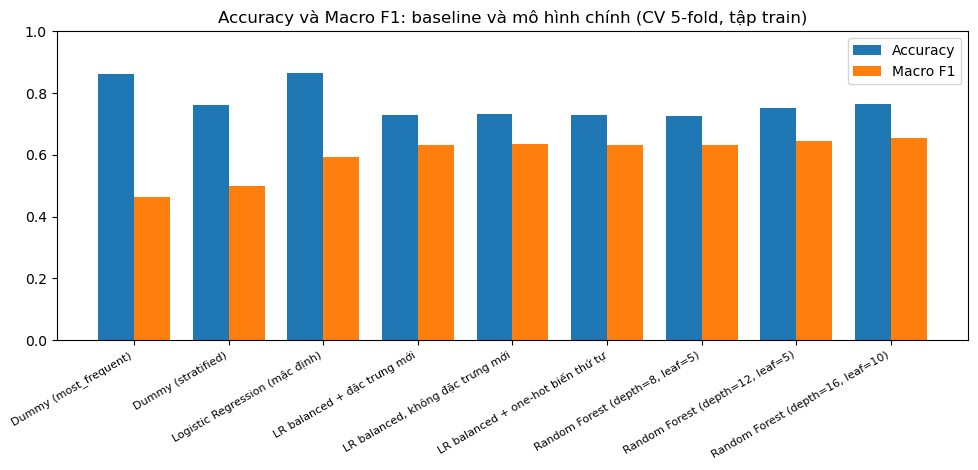

In [9]:
all_res = pd.concat([base_res, res07], ignore_index=True)
comparison = to_table(all_res)
display(comparison)

res07.to_csv(LOG_DIR / "results_07_main_models.csv", index=False, encoding="utf-8-sig")
comparison.to_csv(LOG_DIR / "bang_so_sanh_giua_ky.csv", index=False, encoding="utf-8-sig")
plot_bars(all_res, "07_so_sanh_macro_f1.png", "Accuracy và Macro F1: baseline và mô hình chính (CV 5-fold, tập train)")

## 7.4 Confusion matrix

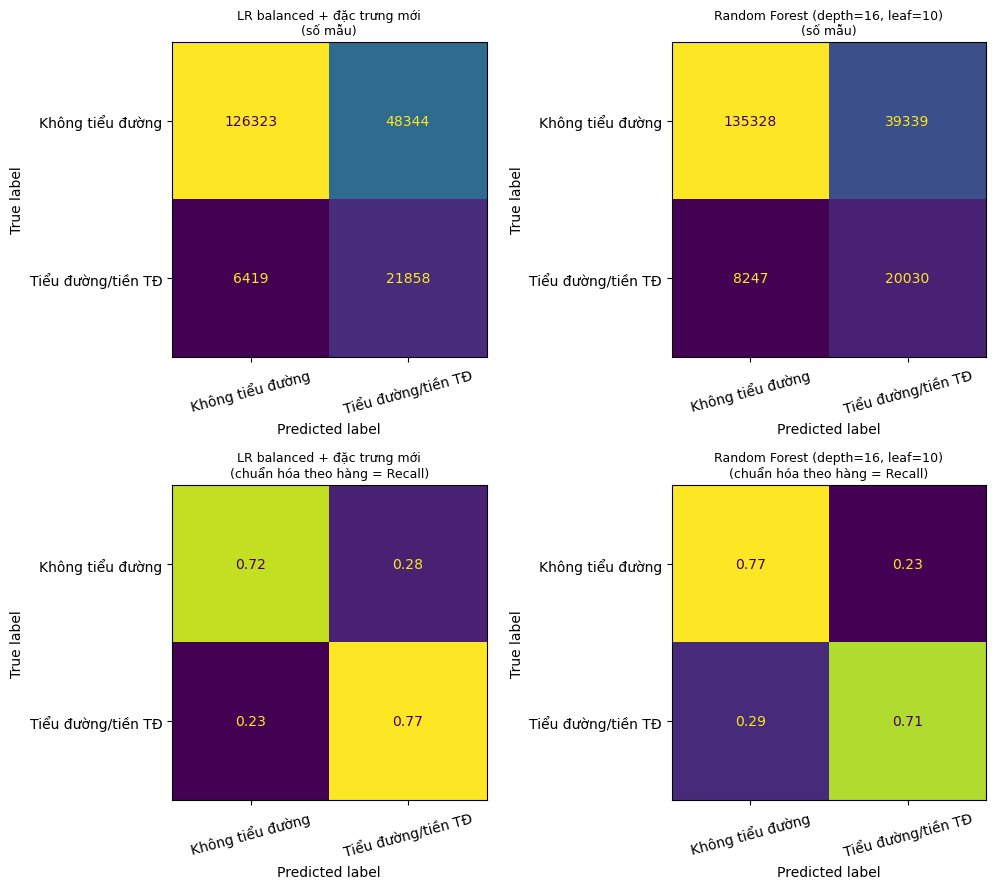

In [10]:
plot_confusion([LR_MAIN, best_rf], "07_confusion_matrix.png")

## 7.5 Đặc trưng mới có giúp không? (so sánh cho mục 4)

In [11]:
a = res07.set_index("Mô hình")
cols = ["Macro F1", "ROC-AUC", "PR-AUC", f"Recall {FOCUS_NAME}", f"F1 {FOCUS_NAME}"]
fe_cmp = a.loc[[LR_MAIN, LR_NOFE], cols]
display(fe_cmp.round(4))
print("Chênh lệch (có đặc trưng mới - không có):")
print((fe_cmp.loc[LR_MAIN] - fe_cmp.loc[LR_NOFE]).round(4).to_string())

,Macro F1,ROC-AUC,PR-AUC,Recall Tiểu đường/tiền TĐ,F1 Tiểu đường/tiền TĐ
Mô hình,,,,,
LR balanced + đặc trưng mới,0.6329,0.8255,0.4217,0.7730,0.4439
"LR balanced, không đặc trưng mới",0.6340,0.8247,0.4191,0.7665,0.4441


Chênh lệch (có đặc trưng mới - không có):
Macro F1                    -0.0011
ROC-AUC                      0.0008
PR-AUC                       0.0026
Recall Tiểu đường/tiền TĐ    0.0065
F1 Tiểu đường/tiền TĐ       -0.0002


## 7.6 Số liệu hỗ trợ viết nhận xét

In [12]:
b = all_res.set_index("Mô hình")
base_only = base_res.set_index("Mô hình")
best_base_name = base_only["Macro F1"].idxmax()
best_base = base_only.loc[best_base_name]
f1_cols = [f"F1 {c}" for c in CLASS_NAMES]

print(f"Baseline tốt nhất: {best_base_name} | Macro F1 = {best_base['Macro F1']:.4f}")
for n in (LR_MAIN, best_rf):
    r = b.loc[n]
    hardest = CLASS_NAMES[int(np.argmin(r[f1_cols].values.astype(float)))]
    print(f"- {n}: Macro F1 = {r['Macro F1']:.4f} (so với baseline {r['Macro F1'] - best_base['Macro F1']:+.4f}) | "
          f"ROC-AUC = {r['ROC-AUC']:.4f} | lớp có F1 thấp nhất: {hardest} | "
          f"Recall {FOCUS_NAME} = {r['Recall ' + FOCUS_NAME]:.3f}, Precision = {r['Precision ' + FOCUS_NAME]:.3f}")
d_f1 = b.loc[best_rf, "Macro F1"] - b.loc[LR_MAIN, "Macro F1"]
d_auc = b.loc[best_rf, "ROC-AUC"] - b.loc[LR_MAIN, "ROC-AUC"]
print(f"\nRF so với LR balanced: Macro F1 {d_f1:+.4f}, ROC-AUC {d_auc:+.4f}")
print(f"Thời gian chạy: LR = {b.loc[LR_MAIN, 'Thời gian (s)']}s, RF = {b.loc[best_rf, 'Thời gian (s)']}s")

Baseline tốt nhất: Logistic Regression (mặc định) | Macro F1 = 0.5928
- LR balanced + đặc trưng mới: Macro F1 = 0.6329 (so với baseline +0.0401) | ROC-AUC = 0.8255 | lớp có F1 thấp nhất: Tiểu đường/tiền TĐ | Recall Tiểu đường/tiền TĐ = 0.773, Precision = 0.311
- Random Forest (depth=16, leaf=10): Macro F1 = 0.6538 (so với baseline +0.0610) | ROC-AUC = 0.8265 | lớp có F1 thấp nhất: Tiểu đường/tiền TĐ | Recall Tiểu đường/tiền TĐ = 0.708, Precision = 0.337

RF so với LR balanced: Macro F1 +0.0209, ROC-AUC +0.0009
Thời gian chạy: LR = 3.8s, RF = 20.1s


### Nhận xét ban đầu (điền bằng số liệu thật sau khi chạy đầy đủ, `QUICK = False`)
1. **Có vượt baseline không?** *(so Macro F1 của LR balanced và RF với baseline tốt nhất ở 7.6; nêu cả ROC-AUC và PR-AUC)*
2. **Lớp hiếm có khó nhất không?** *(xem F1, Recall, Precision của lớp hiếm; giải thích: lớp chiếm tỷ lệ nhỏ, đặc trưng chồng lấn giữa hai lớp. Nếu dùng 3 lớp thì nêu riêng lớp Tiền tiểu đường)*
3. **Random Forest so với Logistic Regression?** *(so Macro F1, ROC-AUC, Recall lớp hiếm, thời gian chạy; LR balanced thường Recall cao nhưng Precision thấp, nên Macro F1 có thể không hơn LR mặc định, hãy nêu rõ sự đánh đổi này)*
4. **Đặc trưng mới có giúp không?** *(dựa vào bảng 7.5; nếu chênh lệch rất nhỏ thì nói thẳng là không đáng kể)*

**Việc còn lại sau giữa kỳ:** tuning kỹ hơn bằng RandomizedSearchCV tối ưu Macro F1, thử SMOTE/undersampling và điều chỉnh ngưỡng, đánh giá một lần trên tập test, SVM/MLP, phân tích lỗi và SHAP.